# Fine-Tuning Visualizations
Loads saved results — no training here. Run after finetune_blocks.ipynb.

Plots:
- Confusion matrices (neural net head, test set)
- ROC curves (neural net head, test set)

In [22]:
import os, sys, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score
)

sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni

device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

Device: mps


In [23]:
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)

with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(
    os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True
)

proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
split     = np.load(os.path.join(SAVE_DIR, 'split.npz'))
train_idx, val_idx, test_idx = split['train_idx'], split['val_idx'], split['test_idx']

ft_results = torch.load(os.path.join(SAVE_DIR, 'ft_results.pt'), weights_only=False)
print(f'Loaded {len(proj_out1)} subjects | Test set: {len(test_idx)} subjects')
print(f'Test labels — Controls: {(labels[test_idx]==0).sum()} | AD: {(labels[test_idx]==1).sum()}')

Loaded 148 subjects | Test set: 15 subjects
Test labels — Controls: 7 | AD: 8


In [24]:
class FinetuneClassifier(nn.Module):
    def __init__(self, encoder_blocks, hidden_dim=256):
        super().__init__()
        self.blocks = encoder_blocks
        self.head = nn.Sequential(
            nn.Linear(hidden_dim * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for block in self.blocks:
            x1 = block(x1)
            x2 = block(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2) / 2).flatten(1))

def get_test_predictions(n_frozen, res):
    """Run the saved fine-tuned model on the test set, return true labels, predicted labels, AD probabilities."""
    model_ft = BrainOmni(**model_config)
    model_ft.load_state_dict(base_checkpoint, strict=False)
    for param in model_ft.parameters():
        param.requires_grad = False
    model_ft = model_ft.to(device).eval()

    unfrozen_ft  = nn.ModuleList(list(model_ft.blocks)[n_frozen:-1])
    ft_classifier = FinetuneClassifier(unfrozen_ft, hidden_dim=256).to(device)
    ft_classifier.load_state_dict(res['best_weights'])
    ft_classifier.eval()

    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for i in test_idx:
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for block in list(model_ft.blocks)[:n_frozen]:
                x1 = block(x1)
                x2 = block(x2)
            logits = ft_classifier(x1, x2)
            probs  = torch.softmax(logits, dim=1)
            y_true.append(labels[i])
            y_pred.append(logits.argmax(1).item())
            y_prob.append(probs[0, 1].item())  # probability of AD

    return np.array(y_true), np.array(y_pred), np.array(y_prob)

print('Helpers ready.')

Helpers ready.


## Confusion Matrices
One matrix per fine-tuning configuration (last 1 / 2 / 3 blocks unfrozen), evaluated on the 15-subject test set.

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


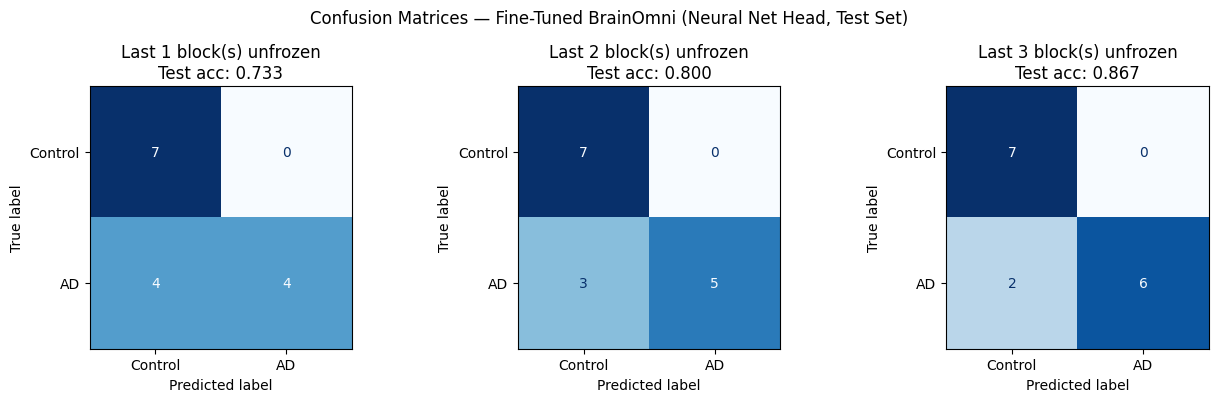

Saved finetune_confusion_matrices.png


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for col, n_frozen in enumerate([10, 9, 8]):
    res = ft_results[n_frozen]
    y_true, y_pred, _ = get_test_predictions(n_frozen, res)

    cm  = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Control', 'AD'])
    disp.plot(ax=axes[col], colorbar=False, cmap='Blues')
    axes[col].set_title(f'Last {res["n_unfrozen"]} block(s) unfrozen\nTest acc: {res["test_acc"]:.3f}')

fig.suptitle('Confusion Matrices — Fine-Tuned BrainOmni (Neural Net Head, Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_confusion_matrices.png'), dpi=150)
plt.show()
print('Saved finetune_confusion_matrices.png')

## ROC Curves
All three configurations on one plot. AUC (area under curve) summarises performance across all decision thresholds — 1.0 is perfect, 0.5 is random.

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


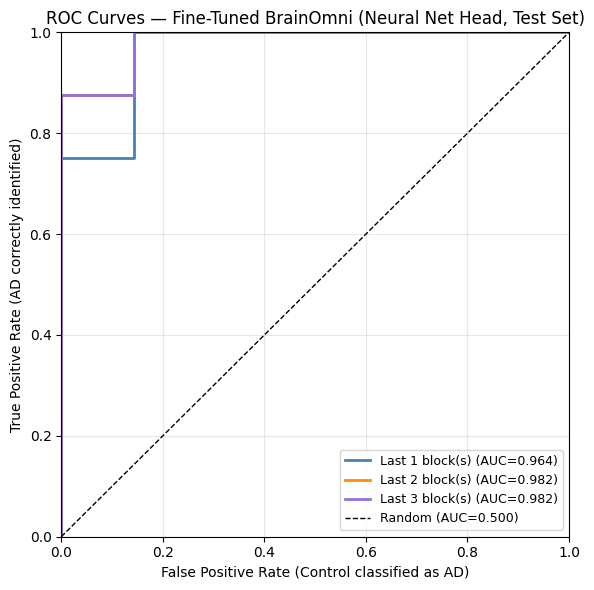

Saved finetune_roc_curves.png


In [26]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = ['steelblue', 'darkorange', 'mediumpurple']

for n_frozen, color in zip([10, 9, 8], colors):
    res = ft_results[n_frozen]
    y_true, _, y_prob = get_test_predictions(n_frozen, res)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    ax.plot(fpr, tpr, color=color, linewidth=2,
            label=f'Last {res["n_unfrozen"]} block(s) (AUC={auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate (Control classified as AD)')
ax.set_ylabel('True Positive Rate (AD correctly identified)')
ax.set_title('ROC Curves — Fine-Tuned BrainOmni (Neural Net Head, Test Set)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_roc_curves.png'), dpi=150)
plt.show()
print('Saved finetune_roc_curves.png')

## 5-Fold CV Comparison (the trustworthy view)\nAll methods evaluated the same way — 5-fold CV over all 148 subjects — so they are directly comparable. Error bars show the standard deviation across the 5 folds (how much the accuracy swings depending on which subjects are held out). The noisy 80/10/10 single-split numbers are intentionally left off this chart; see the table below for those.

In [ ]:
from matplotlib.patches import Patch

lr_data       = torch.load(os.path.join(SAVE_DIR, 'ft_lr_results.pt'), weights_only=False)
ft_cv_results = lr_data['ft_cv_results']
ft_cv_folds   = lr_data.get('ft_cv_folds', None)

# Baselines (5-fold CV) from evaluation.ipynb
FROZEN_CV    = 0.831
HANDCRAFT_CV = 0.872

# One evaluation method only (5-fold CV) so all bars are directly comparable
cats = ['Fine-tune\n(last 1)', 'Fine-tune\n(last 2)', 'Fine-tune\n(last 3)',
        'Frozen\nBrainOmni', 'Handcrafted']
vals = [ft_cv_results[10], ft_cv_results[9], ft_cv_results[8], FROZEN_CV, HANDCRAFT_CV]
if ft_cv_folds is not None:
    errs = [np.std(ft_cv_folds[10]), np.std(ft_cv_folds[9]), np.std(ft_cv_folds[8]), 0, 0]
else:
    errs = [0, 0, 0, 0, 0]

# Color by entity: fine-tuned (blue) vs the two baselines (green frozen, red handcrafted)
FT_C, FROZEN_C, HAND_C = '#4E79A7', '#59A14F', '#E15759'
colors = [FT_C, FT_C, FT_C, FROZEN_C, HAND_C]

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(range(5), vals, width=0.68, color=colors,
              yerr=errs, capsize=4, error_kw=dict(ecolor='#555', lw=1.2))

# Frozen-baseline reference line so you can read fine-tune sitting just below it
ax.axhline(FROZEN_CV, color=FROZEN_C, ls='--', lw=1, alpha=0.55, zorder=0)

for b, v, e in zip(bars, vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, v + e + 0.012,
            f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222')

ax.set_xticks(range(5))
ax.set_xticklabels(cats, fontsize=9)
ax.set_ylabel('Accuracy (5-fold CV)')
ax.set_ylim(0.5, 1.0)
ax.set_title('BrainOmni-tiny on AD Classification — 5-fold CV (148 subjects)', fontsize=12)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Patch(color=FT_C, label='Fine-tuned BrainOmni'),
                   Patch(color=FROZEN_C, label='Frozen BrainOmni (baseline)'),
                   Patch(color=HAND_C, label='Handcrafted features (baseline)')],
          fontsize=8, loc='lower left', frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'finetune_cv_comparison.png'), dpi=150)
plt.show()
print('Saved finetune_cv_comparison.png')
print('\nFor reference, the noisy 80/10/10 single-split numbers (do NOT rank on these):')
for nf in [10, 9, 8]:
    n_un = 11 - nf
    print(f'  Last {n_un} block(s): NN head {ft_results[nf][\"test_acc\"]:.3f} | '
          f'LR {lr_data[\"ft_lr_results\"][nf][\"test_acc\"]:.3f}')